# End-to-end: regression

This notebook runs one regression job from the question to the report, on hourly bike rentals in Washington, D.C. It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 6, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A bike-sharing company moves bikes between its stations by van. The operations planner asks: **how many bikes will people rent in a given hour**, given the time, the day and the weather? With too few bikes at a station, customers walk away; with too many, the vans drive for nothing.

A fixed guess such as "the average hour" ignores rush hours, weekends and rain. A model can learn from two years of records how demand changes with these inputs. The answer is a number, so this is a **regression** problem.

## 2 Load the data

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [1]:
# matplotlib draws the figures, pandas holds tables (DataFrames)
import matplotlib.pyplot as plt
import pandas as pd
# fetch_openml downloads a data set from the OpenML website
from sklearn.datasets import fetch_openml

The Bike Sharing Demand data (Capital Bikeshare, Washington, D.C., 2011 and 2012) has one row per hour. `fetch_openml(data_id=42712, as_frame=True)` reads it from OpenML as a DataFrame. The first call downloads about 1 MB and keeps a copy in `~/scikit_learn_data`, so later calls work offline.

In [2]:
# Load the bike data as a DataFrame; .frame keeps features and target in one table
try:
    bikes = fetch_openml(data_id=42712, as_frame=True).frame
# Without internet and without a saved copy, stop with a clear message
except Exception as error:
    raise RuntimeError("The bike data are not cached yet: run this cell once with internet access.") from error

# shape is (number of rows, number of columns)
print(bikes.shape)

(17379, 13)


**What is in the data?** One row is one hour of one day in 2011 or 2012. It holds the calendar, the weather in that hour and the number of bikes rented. The notebook uses all 13 columns; the source also splits `count` into casual and registered users, but this version of the data does not contain that split. Meanings and units follow the OpenML description of the data.

| Column | Meaning | Values or unit |
|---|---|---|
| `season` | season, as the source labels it | `spring`, `summer`, `fall`, `winter`; the labels are one season ahead of the calendar: `spring` holds late December to mid-March, `winter` late September to late December |
| `year` | year | 0 = 2011, 1 = 2012 |
| `month` | month | 1 (January) to 12 (December) |
| `hour` | hour of the day | 0 to 23 |
| `holiday` | the day is a public holiday in Washington, D.C. | `True` or `False` |
| `weekday` | day of the week | 0 = Sunday to 6 = Saturday (1 January 2011, a Saturday, has 6) |
| `workingday` | the day is neither a weekend day nor a holiday | `True` or `False` |
| `weather` | the weather in that hour | `clear`: clear or a few clouds; `misty`: mist or clouds; `rain`: light rain or light snow, sometimes with thunder; `heavy_rain`: heavy rain, ice pellets, thunderstorm, or snow and fog (only 3 hours) |
| `temp` | air temperature | degrees Celsius, 0.8 to 41 |
| `feel_temp` | felt temperature (how warm or cold it feels) | degrees Celsius, 0 to 50 |
| `humidity` | relative humidity of the air | a share from 0 to 1 |
| `windspeed` | wind speed | 0 to 57; the source gives no unit |
| `count` | **the target**: the number of bikes rented in that hour | 1 to 977 bikes |

## 3 Look at the data

`head()` shows the first rows of the whole table.

In [3]:
# Show the first five rows
bikes.head()

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0,16
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0,40
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0,32
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0,13
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0,1


`describe()` summarises the target: its mean, spread and range in bikes per hour.

In [4]:
# Mean, standard deviation, minimum, quartiles and maximum of the target
bikes["count"].describe().round(1)

count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: count, dtype: float64

The hour of the day matters most. `groupby(["hour", "workingday"])["count"].mean()` gives the average rentals per hour and kind of day, and `unstack()` turns the kinds of day into two columns, one line each in the plot.

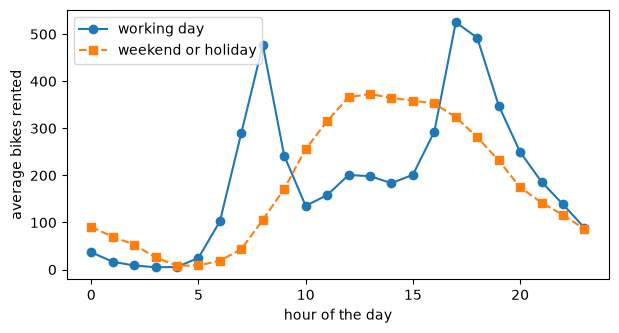

In [5]:
# Average rentals for every (hour, kind of day) pair; unstack() makes one column per kind of day
rentals_by_hour = bikes.groupby(["hour", "workingday"], observed=True)["count"].mean().unstack()

# One line per kind of day: working days, then weekends and holidays
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rentals_by_hour.index, rentals_by_hour["True"], marker="o", label="working day")
ax.plot(rentals_by_hour.index, rentals_by_hour["False"], marker="s", linestyle="--", label="weekend or holiday")
ax.set_xlabel("hour of the day")
ax.set_ylabel("average bikes rented")
ax.legend()
plt.show()

**What do you see?** On working days, demand has two peaks, at 8 in the morning and at 5 to 6 in the evening: people ride to work and back. On other days there is one broad peak from late morning to the afternoon. The effect of the hour depends on the kind of day, which a model has to capture.

## 4 Split the data

We hold back a fifth of the hours as the **test set** and use it once, at the end. `train_test_split` shuffles the rows first; `random_state=0` makes the split the same every time. `X` holds the features and `y` the target.

In [6]:
from sklearn.model_selection import train_test_split

# X: the features (every column except the target); y: the target, bikes rented per hour
X = bikes.drop(columns="count")
y = bikes["count"]
# Keep 20% of the hours as the test set; random_state=0 gives the same split every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(len(X_train), "training hours,", len(X_test), "test hours")

13903 training hours, 3476 test hours


## 5 Process the data

The columns are of two kinds, so a `ColumnTransformer` treats each kind with its own step:

- **Numbers** (`temp`, `feel_temp`, `humidity`, `windspeed`, `year`) are on different scales. `StandardScaler` gives each a mean of 0 and a standard deviation of 1, so the penalty of ridge regression in step 6 treats them alike.
- **Calendar and weather categories** (`hour`, `weekday`, `month`, `season`, `holiday`, `workingday`, `weather`). For a linear model, hour 16 is not "twice hour 8". `OneHotEncoder` gives each hour, weekday and month its own 0/1 column, so each gets its own coefficient.

The transformer learns the means and the categories from the training set only, when it is fitted.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Which columns are numbers and which are categories: each kind gets its own processing
numeric_columns = ["temp", "feel_temp", "humidity", "windspeed", "year"]
category_columns = ["hour", "weekday", "month", "season", "holiday", "workingday", "weather"]

# A ColumnTransformer applies one step per group of columns and puts the results side by side:
# StandardScaler gives each number a mean of 0 and a standard deviation of 1,
# OneHotEncoder turns each category value into its own 0/1 column
# (handle_unknown="ignore": a value never seen in training becomes all zeros instead of an error)
linear_preprocessing = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_columns),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_columns),
])
# fit_transform learns the means and the categories from the training set and returns the
# processed table as an array; we print only its shape (rows, columns)
print(linear_preprocessing.fit_transform(X_train).shape)

(13903, 60)


The 12 columns become 60: five numbers and one 0/1 column per category value. Trees need none of this: they split on thresholds, so scale does not matter, and `HistGradientBoostingRegressor(categorical_features="from_dtype")` treats the pandas `category` columns (`season`, `holiday`, `workingday`, `weather`) as categories by itself.

## 6 Run the pipeline

We start with the simplest model, score it, and then improve it one step at a time: a linear regression, the same model tuned with a grid search, and then a more flexible model. The five decisions of the three models:

| Decision | Linear regression | Ridge regression | Gradient boosting |
|---|---|---|---|
| Data | training hours: calendar and weather features X, bikes rented y | the same | the same |
| Model | a weighted sum of the 60 processed columns | the same | a sum of many small regression trees |
| Loss function | squared error | squared error plus an L2 penalty of strength `alpha` | squared error |
| Optimizer | a formula (least squares, solved exactly) | a formula (a linear system solved exactly) | gradient boosting: each new tree fits the remaining errors; split points from histograms |
| Evaluation | MAE, RMSE and R² on the test set; a plot of predicted against true rentals | the same; `GridSearchCV` chooses `alpha` | the same; `GridSearchCV` chooses the tree settings |

Every model in 6.1 to 6.3 is scored in the same way, with three measures from `sklearn.metrics`:

- **MAE** (`mean_absolute_error`): the average miss, in bikes per hour.
- **RMSE** (`root_mean_squared_error`): the square root of the average squared miss, also in bikes per hour. Large misses count more than in the MAE.
- **R²** (`r2_score`): the share of the variation in rentals that the model explains. 0 means no better than the average, 1 means perfect predictions.

Each section then plots the predicted rentals against the true rentals of the test hours. Points on the dashed line are perfect predictions. The scores go into a dictionary per model (`linear_scores`, `ridge_scores`, `boosting_scores`), from which step 7 builds its table.

### 6.1 Linear regression

`LinearRegression` learns one weight per processed column and predicts their weighted sum. A `Pipeline` chains the preprocessing of step 5 and the model, so `fit` learns both from the training set, and `predict` applies both to new rows.

linear regression: MAE 76.1, RMSE 102.3, R² 0.69


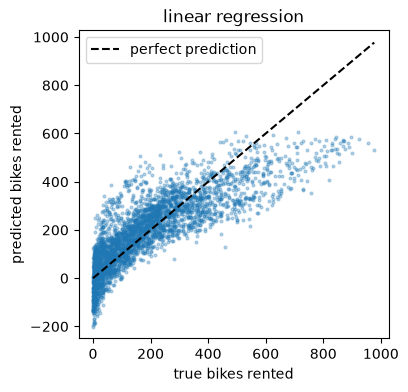

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline

# A Pipeline runs its steps in order: first the preprocessing of step 5, then the model
linear_pipeline = Pipeline([("preprocessing", linear_preprocessing), ("linear", LinearRegression())])
# fit learns the preprocessing and the weights from the training set
linear_pipeline.fit(X_train, y_train)
# Predict the bikes rented for every test hour
linear_predictions = linear_pipeline.predict(X_test)
# Each metric compares the true values with the predictions; step 7 builds its table from this dictionary
linear_scores = {
    "model": "linear regression",
    "MAE": mean_absolute_error(y_test, linear_predictions),
    "RMSE": root_mean_squared_error(y_test, linear_predictions),
    "R²": r2_score(y_test, linear_predictions),
}
print(f"linear regression: MAE {linear_scores['MAE']:.1f}, RMSE {linear_scores['RMSE']:.1f}, R² {linear_scores['R²']:.2f}")

# One point per test hour: true value on the x-axis, prediction on the y-axis
largest_count = y_test.max()
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(y_test, linear_predictions, s=4, alpha=0.3)
# The dashed diagonal: points on it are perfect predictions
ax.plot([0, largest_count], [0, largest_count], linestyle="--", color="black", label="perfect prediction")
# The same axis limits in 6.1 to 6.3, so the plots can be compared
ax.set_xlim(-50, largest_count + 50)
ax.set_ylim(-250, largest_count + 50)
ax.set_xlabel("true bikes rented")
ax.set_ylabel("predicted bikes rented")
ax.set_title("linear regression")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The linear model misses by 76.1 bikes per hour on average and explains 69% of the variation (R² 0.69). The plot shows two patterns. In busy hours above about 600 bikes, all predictions stay too low. In quiet hours, some predictions are below 0, which is impossible for a count.

### 6.2 Tune the linear model with a grid search

Ridge regression is linear regression with a penalty on large weights. Its strength `alpha` is a **hyperparameter**: we choose it, the model does not learn it. `GridSearchCV` tries each value in a list and keeps the best one. It scores each value on parts of the training set only, so the test set stays unseen until we score the winner.

- `{"ridge__alpha": [0.1, 1, 10, 100]}` is the grid: `ridge__alpha` means the argument `alpha` of the step named `ridge`.
- `scoring="neg_mean_absolute_error"` chooses by MAE. It is negated because scikit-learn always maximizes a score.
- After the search, `best_params_` is the chosen value and `best_estimator_` is the pipeline refitted with it on the whole training set.

chosen: {'ridge__alpha': 10}
ridge regression, tuned: MAE 76.0, RMSE 102.3, R² 0.69


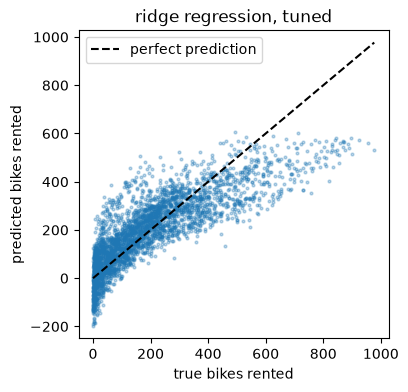

In [9]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# The same pipeline, with Ridge (linear regression with a penalty) as the model
ridge_pipeline = Pipeline([("preprocessing", linear_preprocessing), ("ridge", Ridge())])
# Try four penalty strengths and keep the one with the lowest MAE on the training set
ridge_search = GridSearchCV(ridge_pipeline, {"ridge__alpha": [0.1, 1, 10, 100]},
                            scoring="neg_mean_absolute_error")
# fit runs the whole search, then refits the best pipeline on all training hours
ridge_search.fit(X_train, y_train)
print("chosen:", ridge_search.best_params_)
# best_estimator_ is the refitted best pipeline; only now do we use the test set
# Predict the bikes rented for every test hour
ridge_predictions = ridge_search.best_estimator_.predict(X_test)
# Each metric compares the true values with the predictions; step 7 builds its table from this dictionary
ridge_scores = {
    "model": "ridge regression, tuned",
    "MAE": mean_absolute_error(y_test, ridge_predictions),
    "RMSE": root_mean_squared_error(y_test, ridge_predictions),
    "R²": r2_score(y_test, ridge_predictions),
}
print(f"ridge regression, tuned: MAE {ridge_scores['MAE']:.1f}, RMSE {ridge_scores['RMSE']:.1f}, R² {ridge_scores['R²']:.2f}")

# One point per test hour: true value on the x-axis, prediction on the y-axis
largest_count = y_test.max()
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(y_test, ridge_predictions, s=4, alpha=0.3)
# The dashed diagonal: points on it are perfect predictions
ax.plot([0, largest_count], [0, largest_count], linestyle="--", color="black", label="perfect prediction")
# The same axis limits in 6.1 to 6.3, so the plots can be compared
ax.set_xlim(-50, largest_count + 50)
ax.set_ylim(-250, largest_count + 50)
ax.set_xlabel("true bikes rented")
ax.set_ylabel("predicted bikes rented")
ax.set_title("ridge regression, tuned")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The grid search chose `alpha = 10`, but the scores barely move: MAE 76.0 instead of 76.1, and the plot looks the same. With about 14,000 training hours and 60 columns, the weights are already stable, so a penalty has little to correct. The limit is the model, not its setting. A weighted sum gives each hour one weight for every kind of day, but step 3 showed that the hour matters differently on working days and on weekends.

### 6.3 A more flexible model: gradient boosting

Gradient boosting adds many small regression trees. A tree can split first on the kind of day and then on the hour, so it can learn the two daily patterns of step 3. Trees need no scaling and no one-hot columns, so this pipeline has the model step only. `categorical_features="from_dtype"` treats the pandas `category` columns as categories.

The grid tries two learning rates (how much each new tree corrects) and two tree sizes (`max_leaf_nodes`), four settings in all.

chosen: {'boosting__learning_rate': 0.1, 'boosting__max_leaf_nodes': 31}
gradient boosting, tuned: MAE 26.8, RMSE 43.5, R² 0.94


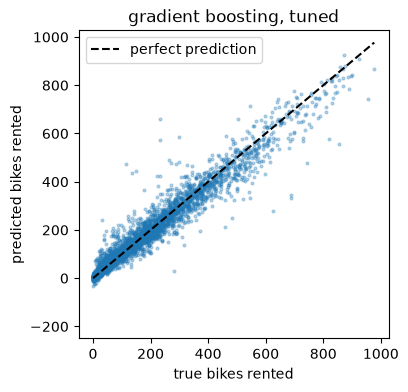

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Trees need no scaling or one-hot columns, so the pipeline has the model step only;
# categorical_features="from_dtype" treats the pandas category columns as categories
boosting_pipeline = Pipeline([
    ("boosting", HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0)),
])
# 2 learning rates × 2 tree sizes = 4 settings to try
boosting_grid = {"boosting__learning_rate": [0.05, 0.1], "boosting__max_leaf_nodes": [15, 31]}
boosting_search = GridSearchCV(boosting_pipeline, boosting_grid, scoring="neg_mean_absolute_error")
boosting_search.fit(X_train, y_train)
print("chosen:", boosting_search.best_params_)
# Predict the bikes rented for every test hour
boosting_predictions = boosting_search.best_estimator_.predict(X_test)
# Each metric compares the true values with the predictions; step 7 builds its table from this dictionary
boosting_scores = {
    "model": "gradient boosting, tuned",
    "MAE": mean_absolute_error(y_test, boosting_predictions),
    "RMSE": root_mean_squared_error(y_test, boosting_predictions),
    "R²": r2_score(y_test, boosting_predictions),
}
print(f"gradient boosting, tuned: MAE {boosting_scores['MAE']:.1f}, RMSE {boosting_scores['RMSE']:.1f}, R² {boosting_scores['R²']:.2f}")

# One point per test hour: true value on the x-axis, prediction on the y-axis
largest_count = y_test.max()
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(y_test, boosting_predictions, s=4, alpha=0.3)
# The dashed diagonal: points on it are perfect predictions
ax.plot([0, largest_count], [0, largest_count], linestyle="--", color="black", label="perfect prediction")
# The same axis limits in 6.1 to 6.3, so the plots can be compared
ax.set_xlim(-50, largest_count + 50)
ax.set_ylim(-250, largest_count + 50)
ax.set_xlabel("true bikes rented")
ax.set_ylabel("predicted bikes rented")
ax.set_title("gradient boosting, tuned")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The grid search chose a learning rate of 0.1 and 31 leaves per tree. The MAE falls from 76.0 to 26.8 bikes per hour, and R² rises to 0.94. The points now lie close to the dashed line, also in busy hours, and no prediction is far below 0. The spread grows with demand: in busy hours the misses are larger in bikes, though not much larger as a share of demand.

## 7 Report the results

One table puts the three models side by side, in the order we built them. Then we ask how sure these numbers are.

In [11]:
# One row per model, built from the score dictionaries of 6.1 to 6.3
test_results = pd.DataFrame([linear_scores, ridge_scores, boosting_scores]).set_index("model").round(2)
test_results

,MAE,RMSE,R²
model,,,
linear regression,76.09,102.34,0.69
"ridge regression, tuned",75.99,102.31,0.69
"gradient boosting, tuned",26.82,43.51,0.94


### 7.1 How sure is each score?

The test set is one sample of hours. Another sample of hours would give slightly different scores. A **95% confidence interval** shows how far a score could move for that reason: over many test sets, 95 of 100 such intervals contain the model's true score.

The MAE has no simple formula for its interval, so we use the **bootstrap**. The fitted models stay fixed; only the test rows are drawn again:

1. Draw as many test rows as there are, **with replacement**: some hours appear twice, some not at all.
2. Compute the MAE on these rows.
3. Repeat 1,000 times. The middle 95% of the 1,000 MAEs, from the 2.5th to the 97.5th percentile, is the interval.

`rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array.

In [12]:
import numpy as np

# The test predictions of every model, computed once: the bootstrap never refits a model
fitted_models = {
    "linear regression": linear_pipeline,
    "ridge regression, tuned": ridge_search.best_estimator_,
    "gradient boosting, tuned": boosting_search.best_estimator_,
}
test_predictions = {}
for model_name, model in fitted_models.items():
    test_predictions[model_name] = model.predict(X_test)

# 1,000 resamples of the test rows; each row of resampled_rows holds the positions of one resample
rng = np.random.default_rng(0)
n_resamples = 1000
n_test_rows = len(y_test)
resampled_rows = rng.integers(0, n_test_rows, size=(n_resamples, n_test_rows))

# The MAE of every model on every resample
true_counts = y_test.to_numpy()
bootstrap_mae = {}
for model_name, predictions in test_predictions.items():
    bootstrap_mae[model_name] = np.array([mean_absolute_error(true_counts[rows], predictions[rows])
                                          for rows in resampled_rows])

# The interval: the 2.5th and the 97.5th percentile of the 1,000 MAEs
interval_rows = []
for model_name, maes in bootstrap_mae.items():
    lower, upper = np.percentile(maes, [2.5, 97.5])
    interval_rows.append({"model": model_name,
                          "MAE": mean_absolute_error(true_counts, test_predictions[model_name]),
                          "95% CI from": lower, "95% CI to": upper})
mae_intervals = pd.DataFrame(interval_rows).set_index("model").round(1)
mae_intervals

,MAE,95% CI from,95% CI to
model,,,
linear regression,76.1,73.9,78.4
"ridge regression, tuned",76.0,73.8,78.3
"gradient boosting, tuned",26.8,25.7,28.0


**What do you see?** Each MAE is uncertain by about ±2 bikes per hour for the two linear models and about ±1 bike for gradient boosting. The intervals of linear and ridge regression overlap almost completely. The interval of gradient boosting, 25.7 to 28.0, lies far below both. Whether two models really differ is a separate question, and section 7.2 answers it.

### 7.2 Is the next model really better? The interval of the difference

To compare two models, we do not compare their two intervals. Both models are scored on the **same** test hours. When the resample happens to hold many easy hours, both models do well; when it holds many hard hours, both do worse. Most of the width of each interval comes from this shared luck, and it cancels when we subtract one score from the other.

So we compute the **gain** of each step on every resample, with the same rows for both models: the MAE of the earlier model minus the MAE of the later one. A positive gain means the later model misses fewer bikes. The middle 95% of the 1,000 gains is the **95% interval of the difference**:

- the interval lies above 0: the later model is better, by about the amount the interval shows;
- the interval contains 0: on this test set we cannot tell the two models apart.

In [13]:
# Each step of section 6, as (short label, earlier model, later model)
steps = [("linear → ridge", "linear regression", "ridge regression, tuned"),
         ("ridge → boosting", "ridge regression, tuned", "gradient boosting, tuned")]

gain_rows = []
for label, earlier, later in steps:
    # The same resampled rows for both models, so every gain compares them on the same hours
    gains = bootstrap_mae[earlier] - bootstrap_mae[later]
    lower, upper = np.percentile(gains, [2.5, 97.5])
    gain_rows.append({"step": label,
                      "gain in MAE": mae_intervals.loc[earlier, "MAE"] - mae_intervals.loc[later, "MAE"],
                      "95% CI from": lower, "95% CI to": upper})
mae_gains = pd.DataFrame(gain_rows).set_index("step").round(2)
mae_gains

,gain in MAE,95% CI from,95% CI to
step,,,
linear → ridge,0.1,0.03,0.18
ridge → boosting,49.2,47.04,51.29


A histogram of the 1,000 gains of each step shows the same thing as a picture. The dashed line marks a gain of 0, "no difference".

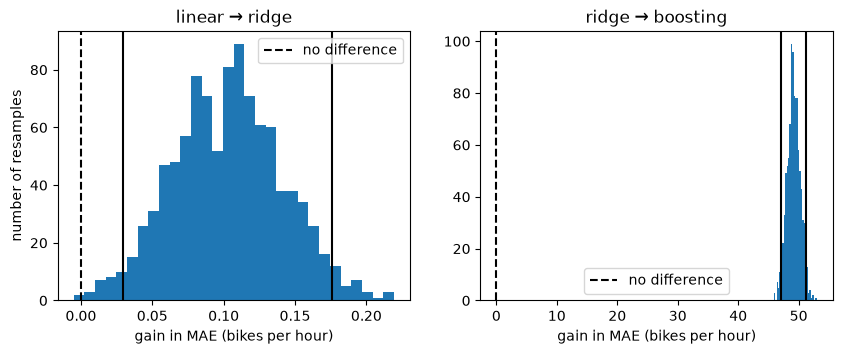

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (label, earlier, later) in zip(axes, steps):
    gains = bootstrap_mae[earlier] - bootstrap_mae[later]
    ax.hist(gains, bins=30)
    # The 95% interval as two solid lines, the value 0 as a dashed line
    for bound in np.percentile(gains, [2.5, 97.5]):
        ax.axvline(bound, color="black")
    ax.axvline(0, color="black", linestyle="--", label="no difference")
    ax.set_title(label)
    ax.set_xlabel("gain in MAE (bikes per hour)")
    ax.legend()
axes[0].set_ylabel("number of resamples")
plt.show()

**What do you see?** Left: tuning the ridge penalty reduces the MAE by 0.03 to 0.18 bikes per hour. The interval lies above 0, so the gain is real, although the two separate intervals in 7.1 overlap almost completely: the shared luck of the test hours cancels in the difference. But a tenth of a bike per hour is of no use to the planner. A difference can be real and still too small to matter.

Right: gradient boosting misses 47.0 to 51.3 fewer bikes per hour than tuned ridge regression. The separate intervals already showed that it is better. The interval of the difference adds **how much** better, with its range, and that is the number the planner needs to decide whether the change is worth it.

**One assumption to check.** The bootstrap treats every test hour as an independent draw. Hours of the same day share their weather, so they are not fully independent, and the intervals above are somewhat too narrow. Resampling whole days instead would widen them. Here the gain of gradient boosting is so large that wider intervals would not change the conclusion.

**Finding.** Tuned gradient boosting predicts the bikes rented in an hour with a mean absolute error of 26.8 bikes on the test hours (95% CI 25.7 to 28.0) and explains 94% of the variation (R² 0.94). It misses 49.2 fewer bikes per hour than tuned ridge regression (95% CI of the difference 47.0 to 51.3), while tuning the ridge penalty gained only 0.1 bikes, a real gain but too small to matter. One limitation: hours of the same day are not independent, so the intervals are somewhat too narrow, and the split mixes hours of the same days into the training set and the test set; a real forecast of tomorrow would do worse, and the forecasting notebook of Session 12 splits by time instead.

## 8 A recent method

Gradient boosting on trees, as above, is still the strong default for tables like this one. A newer idea is a **tabular foundation model**. TabPFN (Hollmann, Müller, Hutter and colleagues, University of Freiburg and Prior Labs, *Nature*, 2025) is a transformer trained in advance on millions of made-up tables. For a new table it predicts in one forward pass, with the training rows as its input, and it needs no tuning. The 2025 paper reports it ahead of tuned gradient boosting on tables of up to 10,000 training rows.

TabPFN is not installed in the course environment. With it, the model step of the pipeline would read:

```python
from tabpfn import TabPFNRegressor

tabpfn_model = TabPFNRegressor(random_state=0).fit(X_train, y_train)
tabpfn_predictions = tabpfn_model.predict(X_test)
```

Compare it with the table above in the same way: the same split and the same scores.

> 📖 **Read more:** [TabPFN paper](https://www.nature.com/articles/s41586-024-08328-6) (Hollmann et al., *Nature* 637, 2025): how the model was trained and where it is better than gradient boosting.